<a href="https://colab.research.google.com/github/dahirahad/Train-price/blob/main/Trainprice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from datasets import load_dataset

ds = load_dataset("animonte/train_house_price")

README.md:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

train.csv:   0%|          | 0.00/461k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1460 [00:00<?, ? examples/s]

In [4]:
# Inspect the dataset structure and splits
print(ds)


DatasetDict({
    train: Dataset({
        features: ['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPor

In [5]:
# Show the first few samples from the training split of the dataset
import pandas as pd

# Convert the default split (often 'train') to a pandas DataFrame for easier preview
split_name = list(ds.keys())[0]
df = pd.DataFrame(ds[split_name].select(range(min(5, len(ds[split_name])))))
display(df)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,None,Reg,Lvl,AllPub,...,0,None,None,None,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,None,Reg,Lvl,AllPub,...,0,None,None,None,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,None,IR1,Lvl,AllPub,...,0,None,None,None,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,None,IR1,Lvl,AllPub,...,0,None,None,None,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,None,IR1,Lvl,AllPub,...,0,None,None,None,0,12,2008,WD,Normal,250000


In [6]:
# Convert the entire train dataset to a Pandas DataFrame
df_full = pd.DataFrame(ds['train'])
print(f"Loaded DataFrame with shape: {df_full.shape}")

# Display basic statistics of numerical columns
df_full[['LotArea', 'GrLivArea', 'OverallQual', 'YearBuilt', 'SalePrice']].describe()

Loaded DataFrame with shape: (1460, 81)


,LotArea,GrLivArea,OverallQual,YearBuilt,SalePrice
count,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,10516.828082,1515.463699,6.099315,1971.267808,180921.195890
std,9981.264932,525.480383,1.382997,30.202904,79442.502883
min,1300.000000,334.000000,1.000000,1872.000000,34900.000000
25%,7553.500000,1129.500000,5.000000,1954.000000,129975.000000
50%,9478.500000,1464.000000,6.000000,1973.000000,163000.000000
75%,11601.500000,1776.750000,7.000000,2000.000000,214000.000000
max,215245.000000,5642.000000,10.000000,2010.000000,755000.000000


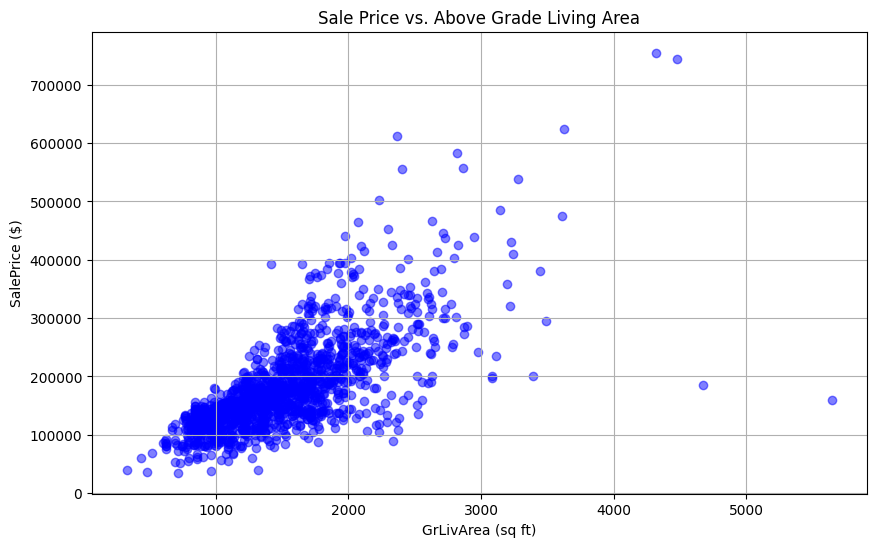

In [7]:
# Visualize relationship between Living Area (GrLivArea) and Sale Price
plt.figure(figsize=(10, 6))
plt.scatter(df_full['GrLivArea'], df_full['SalePrice'], alpha=0.5, color='blue')
plt.title('Sale Price vs. Above Grade Living Area')
plt.xlabel('GrLivArea (sq ft)')
plt.ylabel('SalePrice ($)')
plt.grid(True)
plt.show()

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import numpy as np

# Select strong numerical features for prediction
features = ['LotArea', 'GrLivArea', 'OverallQual', 'YearBuilt', 'TotRmsAbvGrd', 'GarageCars']
X = df_full[features].fillna(0)  # Fill any missing values
y = df_full['SalePrice']

# Split data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# Train a Random Forest model
model = RandomForestRegressor(random_state=42, n_estimators=100)
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_val)

# Evaluate the model
mae = mean_absolute_error(y_val, y_pred)
r2 = r2_score(y_val, y_pred)
print(f"Validation Mean Absolute Error: ${mae:,.2f}")
print(f"Validation R2 Score (Accuracy): {r2:.4f}")

Validation Mean Absolute Error: $20,464.28
Validation R2 Score (Accuracy): 0.8769


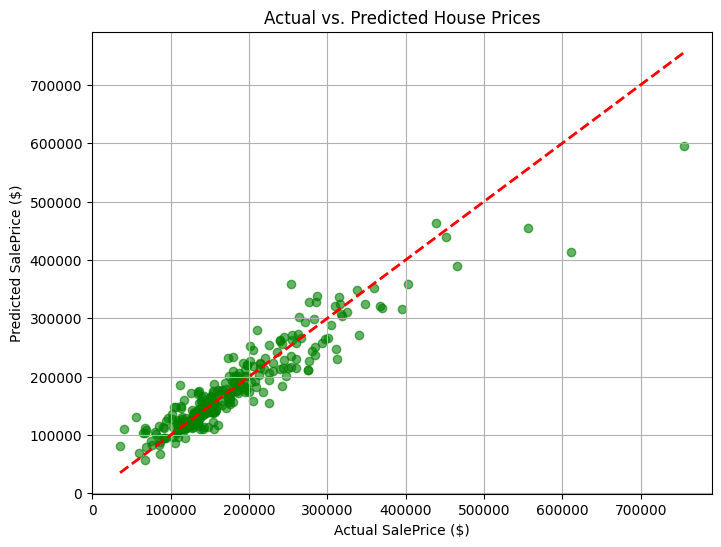

In [9]:
# Plot Predicted vs. Actual House Prices
plt.figure(figsize=(8, 6))
plt.scatter(y_val, y_pred, alpha=0.6, color='green')
plt.plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()], 'r--', lw=2)
plt.title('Actual vs. Predicted House Prices')
plt.xlabel('Actual SalePrice ($)')
plt.ylabel('Predicted SalePrice ($)')
plt.grid(True)
plt.show()

In [10]:
import matplotlib.pyplot as plt
